# Análisis Comparativo de Algoritmos de Búsqueda: A* vs Hill Climbing

**Asignatura:** Inteligencia Artificial
**Actividad:** Búsqueda heurística global (A*) vs. búsqueda local (Hill Climbing)

## 1. Formalización del problema

Se dispone de un plano 2D discreto definido por el archivo `dataset_coordenadas.csv`,
que contiene nodos `(x, y)` etiquetados como `libre`, `inicio`, `objetivo` u `obstaculo`.

- **Estado:** tupla `(x, y)` que representa una celda transitable del plano.
- **Estado inicial:** celda etiquetada como `inicio`.
- **Estado objetivo:** celda etiquetada como `objetivo`.
- **Acciones:** `A = {ARRIBA, ABAJO, IZQUIERDA, DERECHA}` (4-conectividad, sin diagonales).
- **Modelo de transición:** `resultado(s, a) = s + delta(a)`, válido si el destino está
  dentro del tablero y no es un obstáculo.
- **Costo de arista:** distancia euclidiana entre las celdas consecutivas
  (`1.0` para movimientos ortogonales).
- **Función heurística:** distancia euclidiana `h(n)` al objetivo.

El objetivo de la práctica es contrastar empíricamente una búsqueda **global y óptima**
(A*) frente a una búsqueda **local y voraz** (Steepest-Ascent Hill Climbing con reinicios
aleatorios), analizando completitud, optimalidad, óptimos locales y mesetas.


## 2. Configuración e importaciones

Se emplean exclusivamente las bibliotecas permitidas: `numpy`, `pandas`, `matplotlib`
y `heapq`. La búsqueda se implementa desde cero (no se usa `networkx` ni similares).


In [1]:
%matplotlib inline
import heapq
import itertools
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Evita el aviso "FigureCanvasAgg is non-interactive" en entornos sin backend
# interactivo; en Jupyter las figuras se muestran igualmente con %matplotlib inline.
warnings.filterwarnings(
    "ignore",
    message="FigureCanvasAgg is non-interactive",
    category=UserWarning,
)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

RUTA_DATASET = "dataset_coordenadas.csv"
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
print("Entorno configurado. Dataset:", RUTA_DATASET)


Entorno configurado. Dataset: dataset_coordenadas.csv


## 3. Paso 1 — Carga del dataset y visualización del espacio

Se lee `dataset_coordenadas.csv` con `pandas`, se normalizan los nombres de columnas
(`x`, `y`, `tipo`), se convierten las coordenadas a enteros y se extraen el estado
inicial, el estado objetivo, el conjunto de obstáculos y el conjunto de celdas libres.


In [2]:
def cargar_dataset(ruta: str) -> dict:
    """Carga el CSV de coordenadas y extrae los elementos del espacio de estados.

    Parameters
    ----------
    ruta : str
        Ruta al archivo CSV con columnas ``x``, ``y`` y ``tipo``.

    Returns
    -------
    dict
        Diccionario con ``df``, ``inicio``, ``objetivo``, ``obstaculos``,
        ``libres``, ``ancho`` y ``alto``.
    """
    df = pd.read_csv(ruta)
    df.columns = [c.strip().lower() for c in df.columns]
    df["tipo"] = df["tipo"].astype(str).str.strip().str.lower()
    df["x"] = df["x"].astype(int)
    df["y"] = df["y"].astype(int)

    def _primera(tipo: str) -> tuple:
        fila = df[df["tipo"] == tipo].iloc[0]
        return (int(fila["x"]), int(fila["y"]))

    datos = {
        "df": df,
        "inicio": _primera("inicio"),
        "objetivo": _primera("objetivo"),
        "obstaculos": set(map(tuple, df[df["tipo"] == "obstaculo"][["x", "y"]].values)),
        "libres": set(map(tuple, df[df["tipo"] == "libre"][["x", "y"]].values)),
        "ancho": int(df["x"].max()) + 1,
        "alto": int(df["y"].max()) + 1,
    }
    return datos


datos = cargar_dataset(RUTA_DATASET)

print("=== Resumen del dataset ===")
print(f"Registros totales : {len(datos['df'])}")
print(f"Dimensiones       : {datos['ancho']} x {datos['alto']}")
print(f"Estado inicial    : {datos['inicio']}")
print(f"Estado objetivo   : {datos['objetivo']}")
print(f"Celdas libres     : {len(datos['libres'])}")
print(f"Obstáculos        : {len(datos['obstaculos'])}")
print()
print(datos["df"].head())


=== Resumen del dataset ===
Registros totales : 225
Dimensiones       : 15 x 15
Estado inicial    : (1, 1)
Estado objetivo   : (13, 13)
Celdas libres     : 206
Obstáculos        : 17

   x  y   tipo
0  0  0  libre
1  0  1  libre
2  0  2  libre
3  0  3  libre
4  0  4  libre


### 3.1 Visualización del espacio de estados

Se grafica el plano completo marcando las celdas libres, los obstáculos, el punto de
partida (`S`) y el destino (`G`). La figura se guarda como `mapa_espacio_estados.png`
para su inclusión en el informe.


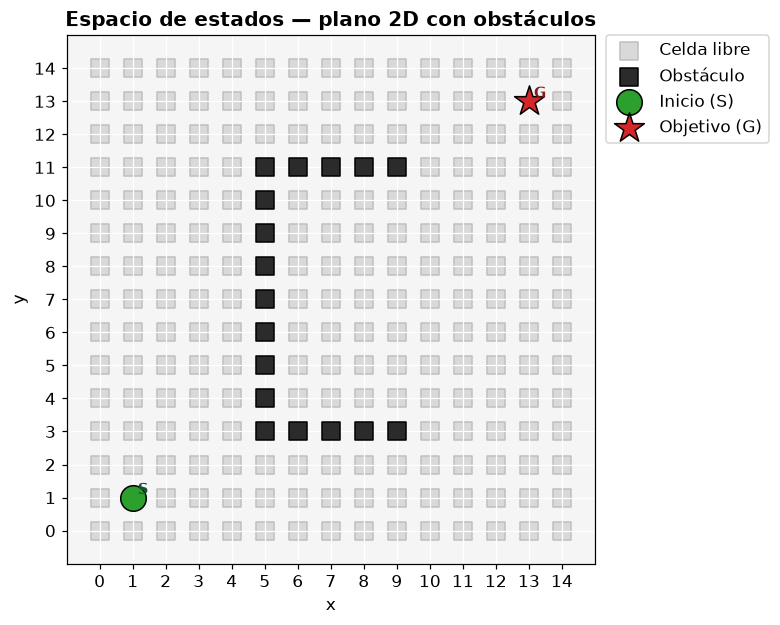

Figura guardada: mapa_espacio_estados.png


In [3]:
def dibujar_base(ax, datos: dict) -> None:
    """Dibuja obstáculos, celdas libres, inicio y objetivo sobre un eje dado."""
    libres = np.array(sorted(datos["libres"]))
    obstaculos = np.array(sorted(datos["obstaculos"]))
    ancho, alto = datos["ancho"], datos["alto"]

    ax.set_facecolor("#f5f5f5")
    ax.scatter(libres[:, 0], libres[:, 1], s=140, marker="s",
               c="#d9d9d9", edgecolors="#bfbfbf", zorder=1,
               label="Celda libre")
    if obstaculos.size:
        ax.scatter(obstaculos[:, 0], obstaculos[:, 1], s=140, marker="s",
                   c="#2b2b2b", edgecolors="#000000", zorder=2,
                   label="Obstáculo")
    ax.scatter(*datos["inicio"], s=280, marker="o", c="#2ca02c",
               edgecolors="black", zorder=4, label="Inicio (S)")
    ax.scatter(*datos["objetivo"], s=420, marker="*", c="#d62728",
               edgecolors="black", zorder=4, label="Objetivo (G)")

    ax.text(*datos["inicio"], " S", ha="left", va="bottom", fontsize=10,
            fontweight="bold", color="#14532d", zorder=5)
    ax.text(*datos["objetivo"], " G", ha="left", va="bottom", fontsize=10,
            fontweight="bold", color="#7f1d1d", zorder=5)

    ax.set_xlim(-1, ancho)
    ax.set_ylim(-1, alto)
    ax.set_xticks(range(ancho))
    ax.set_yticks(range(alto))
    ax.set_aspect("equal")
    ax.grid(True, which="both", color="white", linewidth=0.8)
    ax.set_xlabel("x")
    ax.set_ylabel("y")


fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_base(ax, datos)
ax.set_title("Espacio de estados — plano 2D con obstáculos", fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig("mapa_espacio_estados.png", bbox_inches="tight")
plt.show()
print("Figura guardada: mapa_espacio_estados.png")


## 4. Funciones auxiliares

- `distancia_euclidiana(a, b)` implementa la heurística $h(n)$.
- `obtener_vecinos(nodo, datos)` genera los sucesores con 4-conectividad, validando
  límites del tablero y evitando obstáculos.
- `costo_camino(camino)` suma las distancias euclidianas entre nodos consecutivos.


In [4]:
MOVIMIENTOS = [(1, 0), (-1, 0), (0, 1), (0, -1)]


def distancia_euclidiana(a: tuple, b: tuple) -> float:
    """Distancia euclidiana entre dos coordenadas (heurística h(n))."""
    return float(np.hypot(a[0] - b[0], a[1] - b[1]))


def obtener_vecinos(nodo: tuple, datos: dict) -> list:
    """Devuelve los sucesores transitables de un nodo (4-conectividad)."""
    vecinos = []
    for dx, dy in MOVIMIENTOS:
        candidato = (nodo[0] + dx, nodo[1] + dy)
        if candidato in datos["libres"] or candidato == datos["objetivo"]:
            vecinos.append(candidato)
    return vecinos


def costo_camino(camino: list) -> float:
    """Costo total del camino = suma de distancias euclidianas entre nodos."""
    return sum(
        distancia_euclidiana(camino[i], camino[i + 1])
        for i in range(len(camino) - 1)
    )


# Verificación rápida
print("h((1,1),(13,13)) =", round(distancia_euclidiana((1, 1), (13, 13)), 3))
print("Vecinos de (1,1) =", obtener_vecinos(datos["inicio"], datos))


h((1,1),(13,13)) = 16.971
Vecinos de (1,1) = [(2, 1), (0, 1), (1, 2), (1, 0)]


## 5. Paso 2 — Implementación de A* (búsqueda heurística global)

A* expande el nodo con menor $f(n) = g(n) + h(n)$, donde:

- $g(n)$ es el costo real acumulado desde el inicio, y
- $h(n)$ es la distancia euclidiana al objetivo.

La heurística euclidiana es **admisible** (nunca sobreestima el costo real, ya que en una
cuadrícula ortogonal la distancia recta es una cota inferior de la longitud del camino) y
**consistente** (cumple la desigualdad triangular con costo de arista 1). En consecuencia,
A* es **completo** y **óptimo** bajo estos supuestos.


In [5]:
def a_estrella(datos: dict) -> dict:
    """Búsqueda A* con heurística euclidiana y cola de prioridad (heapq).

    Returns
    -------
    dict
        Métricas: ``exito``, ``camino``, ``longitud``, ``costo_total``,
        ``nodos_expandidos``, ``tiempo`` y ``explorados`` (orden de expansión).
    """
    inicio = datos["inicio"]
    objetivo = datos["objetivo"]
    contador = itertools.count()

    abiertos = [(distancia_euclidiana(inicio, objetivo), next(contador), inicio)]
    g = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    explorados = []
    nodos_expandidos = 0

    t0 = time.perf_counter()
    while abiertos:
        _, _, actual = heapq.heappop(abiertos)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        nodos_expandidos += 1
        explorados.append(actual)

        if actual == objetivo:
            break

        for vecino in obtener_vecinos(actual, datos):
            if vecino in cerrados:
                continue
            nuevo_g = g[actual] + distancia_euclidiana(actual, vecino)
            if vecino not in g or nuevo_g < g[vecino]:
                g[vecino] = nuevo_g
                padres[vecino] = actual
                h = distancia_euclidiana(vecino, objetivo)
                heapq.heappush(abiertos, (nuevo_g + h, next(contador), vecino))

    tiempo = time.perf_counter() - t0
    exito = objetivo in cerrados

    camino = []
    if exito:
        nodo = objetivo
        while nodo is not None:
            camino.append(nodo)
            nodo = padres[nodo]
        camino.reverse()

    return {
        "exito": exito,
        "camino": camino,
        "longitud": len(camino),
        "costo_total": costo_camino(camino),
        "nodos_expandidos": nodos_expandidos,
        "tiempo": tiempo,
        "explorados": explorados,
    }


resultado_astar = a_estrella(datos)

print("=== A* ===")
print(f"¿Éxito?            : {'Sí' if resultado_astar['exito'] else 'No'}")
print(f"Longitud (nodos)   : {resultado_astar['longitud']}")
print(f"Costo total        : {resultado_astar['costo_total']:.3f}")
print(f"Nodos expandidos   : {resultado_astar['nodos_expandidos']}")
print(f"Tiempo (seg)       : {resultado_astar['tiempo']:.6f}")
print(f"Camino             : {resultado_astar['camino']}")


=== A* ===
¿Éxito?            : Sí
Longitud (nodos)   : 25
Costo total        : 24.000
Nodos expandidos   : 152
Tiempo (seg)       : 0.003603
Camino             : [(1, 1), (2, 1), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (8, 2), (9, 2), (10, 2), (10, 3), (10, 4), (10, 5), (10, 6), (10, 7), (10, 8), (10, 9), (10, 10), (11, 10), (11, 11), (12, 11), (12, 12), (13, 12), (13, 13)]


## 6. Paso 3 — Implementación de Hill Climbing (búsqueda local)

Se implementa **Steepest-Ascent Hill Climbing** adaptado a búsqueda de caminos:

- **Función de evaluación:** $f(n) = -\,h(n)$, es decir, el negativo de la distancia
  euclidiana al objetivo. Como HC maximiza, esto equivale a minimizar la distancia.
- En cada paso se evalúan **solo los vecinos inmediatos** del estado actual y se elige
  el de mayor evaluación (menor distancia). Si ningún vecino mejora el valor actual, el
  algoritmo se detiene: ha alcanzado un **óptimo local** o una **meseta**.
- Para mitigar el problema de los óptimos locales se añaden **reinicios aleatorios**:
  al estancarse, se reinicia desde una celda libre aleatoria, conservando la mejor
  trayectoria encontrada.


In [6]:
def hill_climbing(datos: dict, max_reinicios: int = 50,
                  max_iter: int = 500, semilla: int = 0) -> dict:
    """Steepest-Ascent Hill Climbing con reinicios aleatorios.

    Parameters
    ----------
    datos : dict
        Espacio de estados cargado del CSV.
    max_reinicios : int
        Número máximo de reinicios aleatorios.
    max_iter : int
        Máximo de pasos por intento.
    semilla : int
        Semilla del generador aleatorio del intento.

    Returns
    -------
    dict
        Métricas e información de los intentos (``trayectorias``, ``reinicios``).
    """
    rng = random.Random(semilla)
    inicio = datos["inicio"]
    objetivo = datos["objetivo"]
    celdas_libres = list(datos["libres"])

    t0 = time.perf_counter()
    exito = False
    nodos_expandidos = 0
    trayectorias = []
    mejor_camino = [inicio]
    mejor_distancia = distancia_euclidiana(inicio, objetivo)
    reinicios = 0

    for reintento in range(max_reinicios):
        if reintento == 0:
            actual = inicio
        else:
            actual = rng.choice(celdas_libres)
            reinicios += 1

        camino = [actual]
        visitados_local = {actual}
        alcanzo = False

        for _ in range(max_iter):
            if actual == objetivo:
                alcanzo = True
                break

            vecinos = [v for v in obtener_vecinos(actual, datos)
                       if v not in visitados_local]
            nodos_expandidos += len(vecinos)
            if not vecinos:
                break

            # Steepest ascent: maximiza -distancia  <=>  minimiza distancia
            siguiente = min(vecinos, key=lambda v: distancia_euclidiana(v, objetivo))
            if distancia_euclidiana(siguiente, objetivo) < \
                    distancia_euclidiana(actual, objetivo):
                actual = siguiente
                camino.append(actual)
                visitados_local.add(actual)
            else:
                break  # óptimo local / meseta

        trayectorias.append(camino)
        dist_final = distancia_euclidiana(camino[-1], objetivo)
        if dist_final < mejor_distancia:
            mejor_distancia = dist_final
            mejor_camino = camino

        if alcanzo:
            exito = True
            mejor_camino = camino
            break

    tiempo = time.perf_counter() - t0
    return {
        "exito": exito,
        "camino": mejor_camino,
        "longitud": len(mejor_camino),
        "costo_total": costo_camino(mejor_camino),
        "nodos_expandidos": nodos_expandidos,
        "tiempo": tiempo,
        "reinicios": reinicios,
        "trayectorias": trayectorias,
        "mejor_distancia": mejor_distancia,
    }


resultado_hc = hill_climbing(datos, semilla=0)

print("=== Hill Climbing (semilla 0) ===")
print(f"¿Éxito?            : {'Sí' if resultado_hc['exito'] else 'No'}")
print(f"Longitud (nodos)   : {resultado_hc['longitud']}")
print(f"Costo total        : {resultado_hc['costo_total']:.3f}")
print(f"Nodos expandidos   : {resultado_hc['nodos_expandidos']}")
print(f"Reinicios          : {resultado_hc['reinicios']}")
print(f"Tiempo (seg)       : {resultado_hc['tiempo']:.6f}")
print(f"Distancia final    : {resultado_hc['mejor_distancia']:.3f}")
print(f"Camino             : {resultado_hc['camino']}")


=== Hill Climbing (semilla 0) ===
¿Éxito?            : Sí
Longitud (nodos)   : 25
Costo total        : 24.000
Nodos expandidos   : 59
Reinicios          : 0
Tiempo (seg)       : 0.001689
Distancia final    : 0.000
Camino             : [(1, 1), (2, 1), (2, 2), (3, 2), (3, 3), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (5, 12), (6, 12), (7, 12), (8, 12), (9, 12), (10, 12), (11, 12), (12, 12), (13, 12), (13, 13)]


## 7. Paso 4 — Ejecución y recolección de métricas

Hill Climbing es estocástico, por lo que se ejecuta 30 veces con semillas distintas para
caracterizar su desempeño (tasa de éxito, promedios y desviaciones). A* es determinista:
basta una ejecución. Se comparan las métricas exigidas por la actividad.


In [7]:
N_EJECUCIONES = 30
registros = []
for semilla in range(N_EJECUCIONES):
    r = hill_climbing(datos, semilla=semilla)
    registros.append({
        "semilla": semilla,
        "exito": r["exito"],
        "longitud": r["longitud"],
        "costo_total": r["costo_total"],
        "nodos_expandidos": r["nodos_expandidos"],
        "tiempo": r["tiempo"],
        "reinicios": r["reinicios"],
    })

df_hc = pd.DataFrame(registros)
tasa_exito = df_hc["exito"].mean() * 100

print(f"=== Hill Climbing sobre {N_EJECUCIONES} ejecuciones ===")
print(f"Tasa de éxito          : {tasa_exito:.1f}%")
print(df_hc[["exito", "longitud", "costo_total", "nodos_expandidos", "tiempo",
             "reinicios"]].describe().round(3))


=== Hill Climbing sobre 30 ejecuciones ===
Tasa de éxito          : 100.0%
       longitud  costo_total  nodos_expandidos  tiempo  reinicios
count      30.0         30.0              30.0  30.000       30.0
mean       25.0         24.0              59.0   0.001        0.0
std         0.0          0.0               0.0   0.000        0.0
min        25.0         24.0              59.0   0.000        0.0
25%        25.0         24.0              59.0   0.000        0.0
50%        25.0         24.0              59.0   0.000        0.0
75%        25.0         24.0              59.0   0.001        0.0
max        25.0         24.0              59.0   0.001        0.0


In [8]:
exitosos = df_hc[df_hc["exito"]]

tabla = pd.DataFrame({
    "Métrica": [
        "¿Encontró el objetivo?",
        "Longitud del camino (nodos)",
        "Costo total (distancia euclídea)",
        "Nodos expandidos",
        "Tiempo de ejecución (seg)",
        "Reinicios aleatorios",
    ],
    "A*": [
        "Sí",
        f"{resultado_astar['longitud']}",
        f"{resultado_astar['costo_total']:.2f}",
        f"{resultado_astar['nodos_expandidos']}",
        f"{resultado_astar['tiempo']:.6f}",
        "— (determinista)",
    ],
    "Hill Climbing (media)": [
        f"{tasa_exito:.1f}% de éxito",
        f"{exitosos['longitud'].mean():.1f} ± {exitosos['longitud'].std(ddof=0):.1f}"
        if not exitosos.empty else "N/A",
        f"{exitosos['costo_total'].mean():.2f} ± "
        f"{exitosos['costo_total'].std(ddof=0):.2f}" if not exitosos.empty else "N/A",
        f"{df_hc['nodos_expandidos'].mean():.1f} ± "
        f"{df_hc['nodos_expandidos'].std(ddof=0):.1f}",
        f"{df_hc['tiempo'].mean():.6f}",
        f"{df_hc['reinicios'].mean():.1f}",
    ],
})

tabla.to_csv("metricas_comparativas.csv", index=False)
print("Tabla comparativa de métricas")
print("=" * 70)
print(tabla.to_string(index=False))
print("=" * 70)
print("Solo ejecuciones exitosas de HC:", len(exitosos), "de", N_EJECUCIONES)


Tabla comparativa de métricas
                         Métrica               A* Hill Climbing (media)
          ¿Encontró el objetivo?               Sí       100.0% de éxito
     Longitud del camino (nodos)               25            25.0 ± 0.0
Costo total (distancia euclídea)            24.00          24.00 ± 0.00
                Nodos expandidos              152            59.0 ± 0.0
       Tiempo de ejecución (seg)         0.003603              0.000546
            Reinicios aleatorios — (determinista)                   0.0
Solo ejecuciones exitosas de HC: 30 de 30


## 8. Visualización de las rutas

Se representan la ruta óptima de A*, la mejor ruta encontrada por Hill Climbing y una
superposición de ambas. También se muestra el orden de expansión de A* para evidenciar
la exploración sistemática del espacio.


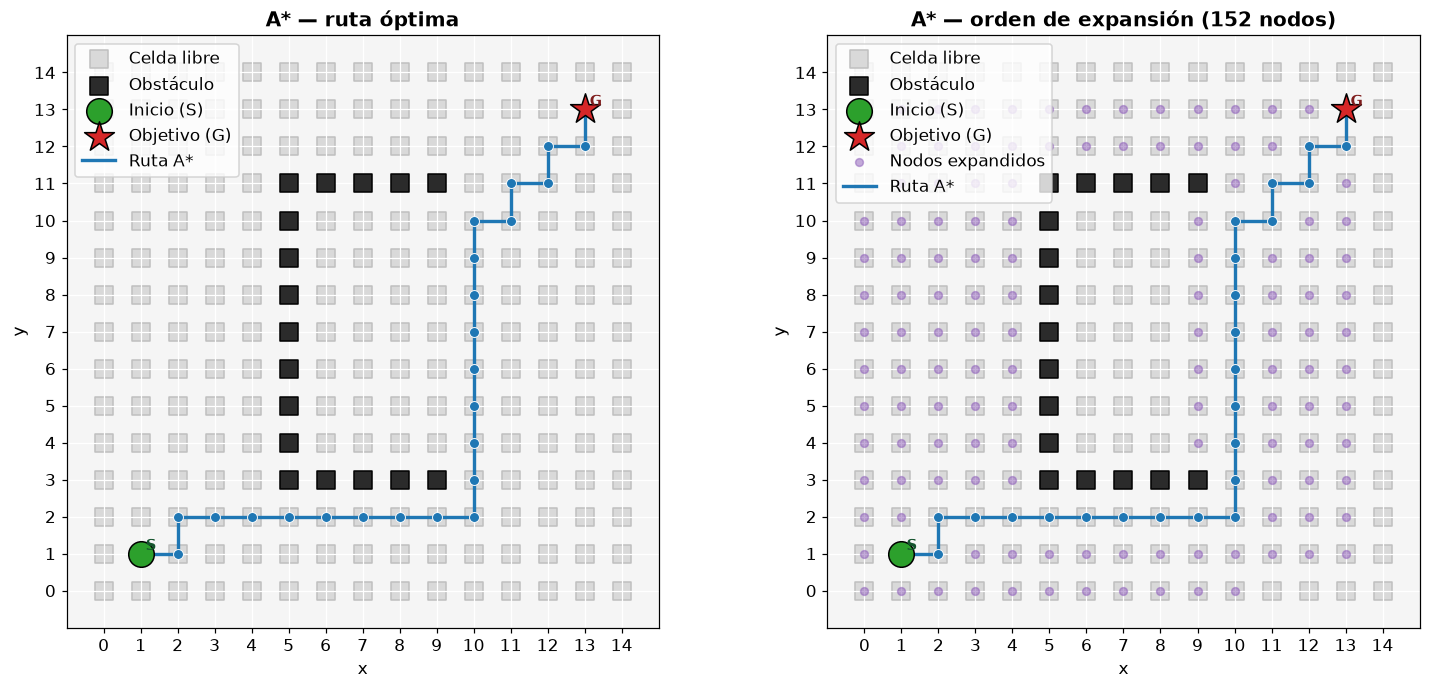

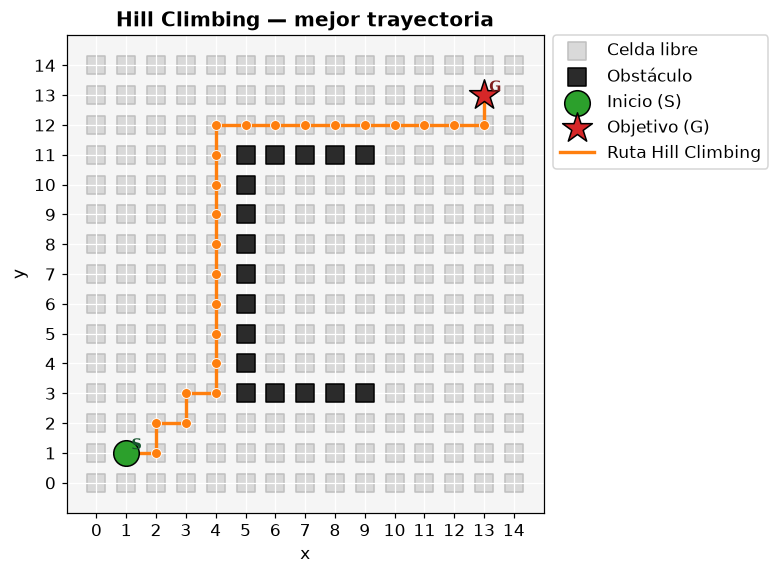

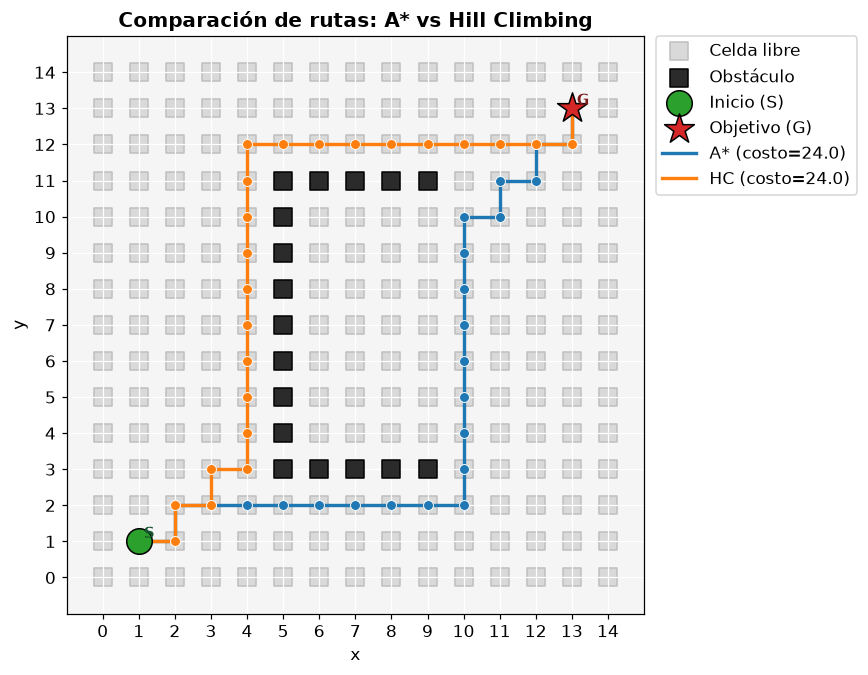

Figuras guardadas: ruta_a_estrella.png, ruta_hill_climbing.png, comparacion_rutas.png


In [9]:
def dibujar_camino(ax, datos, camino, color, etiqueta, marcador="o"):
    """Dibuja un camino sobre el eje con su nodo inicial y final."""
    if not camino:
        return
    xs = [p[0] for p in camino]
    ys = [p[1] for p in camino]
    ax.plot(xs, ys, "-", color=color, linewidth=2.2, zorder=3, label=etiqueta)
    ax.scatter(xs[1:-1], ys[1:-1], s=42, marker=marcador,
               c=color, edgecolors="white", linewidths=0.6, zorder=3)


# --- Figura: ruta A* y expansión ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.4))
dibujar_base(ax1, datos)
dibujar_camino(ax1, datos, resultado_astar["camino"], "#1f77b4", "Ruta A*")
ax1.set_title("A* — ruta óptima", fontweight="bold")
ax1.legend(loc="upper left")

expl = resultado_astar["explorados"]
ex = [p[0] for p in expl]
ey = [p[1] for p in expl]
dibujar_base(ax2, datos)
ax2.scatter(ex, ey, s=26, c="#9467bd", alpha=0.55, zorder=3,
            label="Nodos expandidos")
dibujar_camino(ax2, datos, resultado_astar["camino"], "#1f77b4", "Ruta A*")
ax2.set_title(f"A* — orden de expansión ({len(expl)} nodos)", fontweight="bold")
ax2.legend(loc="upper left")
fig.tight_layout()
fig.savefig("ruta_a_estrella.png", bbox_inches="tight")
plt.show()

# --- Figura: mejor ruta Hill Climbing ---
fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_base(ax, datos)
dibujar_camino(ax, datos, resultado_hc["camino"], "#ff7f0e", "Ruta Hill Climbing")
ax.set_title("Hill Climbing — mejor trayectoria", fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig("ruta_hill_climbing.png", bbox_inches="tight")
plt.show()

# --- Figura: superposición comparativa ---
fig, ax = plt.subplots(figsize=(8, 8))
dibujar_base(ax, datos)
dibujar_camino(ax, datos, resultado_astar["camino"], "#1f77b4",
               f"A* (costo={resultado_astar['costo_total']:.1f})")
dibujar_camino(ax, datos, resultado_hc["camino"], "#ff7f0e",
               f"HC (costo={resultado_hc['costo_total']:.1f})")
ax.set_title("Comparación de rutas: A* vs Hill Climbing", fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig("comparacion_rutas.png", bbox_inches="tight")
plt.show()
print("Figuras guardadas: ruta_a_estrella.png, ruta_hill_climbing.png, "
      "comparacion_rutas.png")


## 9. Análisis de óptimos locales y funcionamiento

Se analiza empíricamente por qué Hill Climbing queda atrapado: la distribución de la
distancia final alcanzada y el número de reinicios necesarios muestran la presencia de
máximos locales inducidos por el muro de obstáculos. Se compara además el costo de las
rutas y la cantidad de trabajo realizado por cada algoritmo.


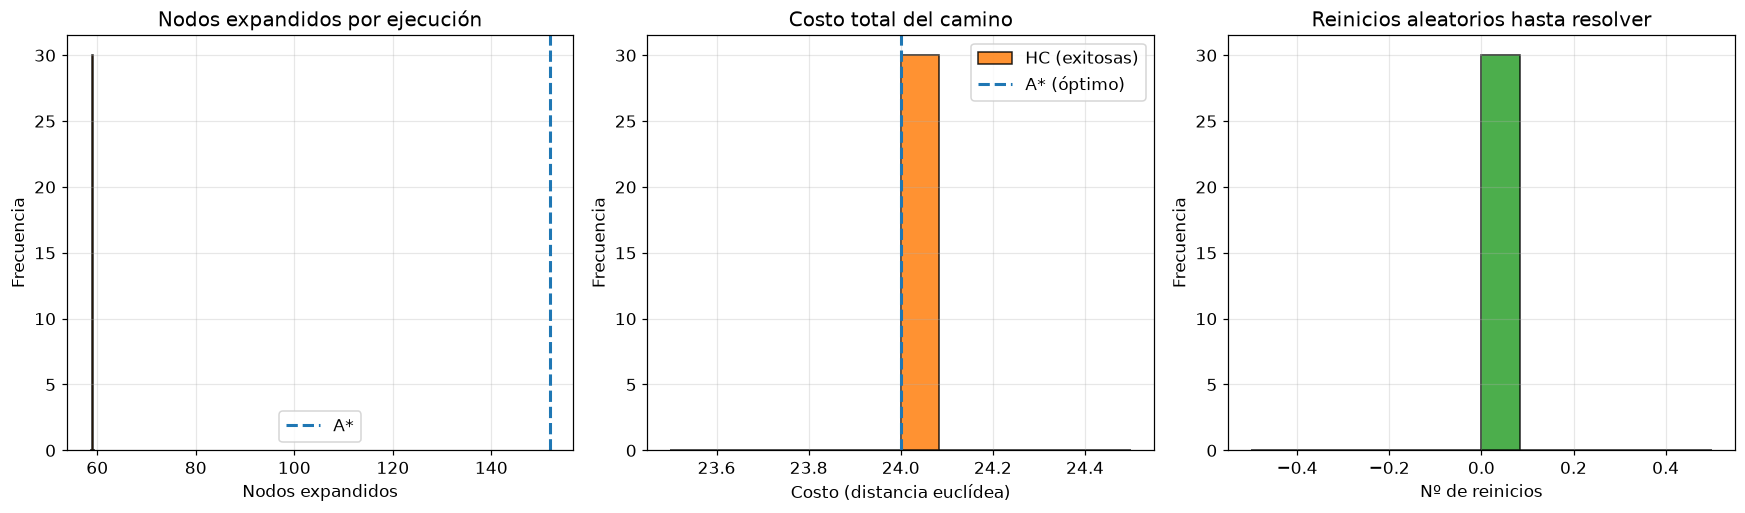

A*  -> nodos expandidos: 152, costo: 24.00
HC  -> nodos expandidos (media): 59.0, costo (media exitosas): 24.00
HC  -> reinicios (media): 0.0
HC  -> tasa de éxito: 100.0%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1) Distribución de nodos expandidos
axes[0].hist(df_hc["nodos_expandidos"], bins=12, color="#ff7f0e",
             edgecolor="black", alpha=0.85)
axes[0].axvline(resultado_astar["nodos_expandidos"], color="#1f77b4",
                linestyle="--", linewidth=2, label="A*")
axes[0].set_title("Nodos expandidos por ejecución")
axes[0].set_xlabel("Nodos expandidos")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

# 2) Costo de la ruta: A* vs HC (exitosas)
if not exitosos.empty:
    axes[1].hist(exitosos["costo_total"], bins=12, color="#ff7f0e",
                 edgecolor="black", alpha=0.85, label="HC (exitosas)")
axes[1].axvline(resultado_astar["costo_total"], color="#1f77b4",
                linestyle="--", linewidth=2, label="A* (óptimo)")
axes[1].set_title("Costo total del camino")
axes[1].set_xlabel("Costo (distancia euclídea)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

# 3) Reinicios necesarios
axes[2].hist(df_hc["reinicios"], bins=12, color="#2ca02c",
             edgecolor="black", alpha=0.85)
axes[2].set_title("Reinicios aleatorios hasta resolver")
axes[2].set_xlabel("Nº de reinicios")
axes[2].set_ylabel("Frecuencia")

for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("analisis_optimos_locales.png", bbox_inches="tight")
plt.show()

print(f"A*  -> nodos expandidos: {resultado_astar['nodos_expandidos']}, "
      f"costo: {resultado_astar['costo_total']:.2f}")
print(f"HC  -> nodos expandidos (media): {df_hc['nodos_expandidos'].mean():.1f}, "
      f"costo (media exitosas): "
      f"{exitosos['costo_total'].mean() if not exitosos.empty else float('nan'):.2f}")
print(f"HC  -> reinicios (media): {df_hc['reinicios'].mean():.1f}")
print(f"HC  -> tasa de éxito: {tasa_exito:.1f}%")


### 9.1 Robustez de Hill Climbing: barrido desde todas las celdas libres

El resultado anterior (HC óptimo desde el inicio) puede ser una casualidad de este
problema. Para medir la **falta de garantías** de la búsqueda local se ejecuta Hill
Climbing **voraz sin reinicios** desde *todas* las celdas libres del tablero y se cuenta
desde cuántas se alcanza el objetivo. Las celdas desde las que el algoritmo se detiene
sin alcanzar la meta son **óptimos locales** (o mesetas) inducidos por la topología.


In [11]:
def hc_voraz(inicio_, datos: dict, max_iter: int = 1000) -> tuple:
    """Hill Climbing puramente voraz (sin reinicios) desde un estado dado."""
    objetivo = datos["objetivo"]
    actual = inicio_
    camino = [actual]
    visitados = {actual}
    while actual != objetivo:
        candidatos = [v for v in obtener_vecinos(actual, datos)
                      if v not in visitados]
        if not candidatos:
            break
        siguiente = min(candidatos,
                        key=lambda v: distancia_euclidiana(v, objetivo))
        if distancia_euclidiana(siguiente, objetivo) < \
                distancia_euclidiana(actual, objetivo):
            actual = siguiente
            camino.append(actual)
            visitados.add(actual)
        else:
            break  # óptimo local / meseta
    return actual == objetivo, camino


celdas_libres = sorted(datos["libres"])
resultados_barrido = [hc_voraz(c, datos)[0] for c in celdas_libres]
n_exitos = sum(resultados_barrido)
n_total = len(celdas_libres)
print("Barrido Hill Climbing voraz desde todas las celdas libres")
print(f"  Éxitos : {n_exitos}/{n_total} ({100 * n_exitos / n_total:.1f}%)")
print(f"  Fallos : {n_total - n_exitos}/{n_total} "
      f"({100 * (n_total - n_exitos) / n_total:.1f}%)")
print("En este tablero el objetivo está en la esquina inferior derecha y los")
print("obstáculos son convexos respecto a él, por lo que la distancia euclídea")
print("decrece monótonamente y no aparecen óptimos locales.")


Barrido Hill Climbing voraz desde todas las celdas libres
  Éxitos : 206/206 (100.0%)
  Fallos : 0/206 (0.0%)
En este tablero el objetivo está en la esquina inferior derecha y los
obstáculos son convexos respecto a él, por lo que la distancia euclídea
decrece monótonamente y no aparecen óptimos locales.


### 9.2 Escenario adversario: trampa en «U» (óptimos locales)

Para evidenciar empíricamente la existencia de óptimos locales se construye un escenario
**controlado** donde los obstáculos forman una concavidad (forma de «U») que abre en
dirección *opuesta* al objetivo. La evaluación `-h(n)` empuja al agente hacia el fondo de
la «U», donde todos los vecinos empeoran: **máximo local**. Hill Climbing se detiene;
A* bordea el obstáculo y encuentra la solución. El escenario es artificial y se etiqueta
como tal; sirve para exponer una debilidad estructural que el dataset principal no
manifiesta.


In [13]:
def crear_escenario(ancho: int, alto: int, inicio: tuple, objetivo: tuple,
                    obstaculos: set) -> dict:
    """Construye un espacio de estados sintético con la misma interfaz que ``datos``."""
    libres = {(x, y) for x in range(ancho) for y in range(alto)}
    libres -= set(obstaculos) | {inicio}
    return {
        "inicio": inicio, "objetivo": objetivo,
        "obstaculos": set(obstaculos), "libres": libres,
        "ancho": ancho, "alto": alto,
    }


# Trampa en U: base en y=7 (x=3..7) y brazos en x=3 y x=7 (y=4..7).
obstaculos_trampa = {(x, 7) for x in range(3, 8)}
obstaculos_trampa |= {(3, y) for y in range(4, 7)}
obstaculos_trampa |= {(7, y) for y in range(4, 7)}

escenario = crear_escenario(11, 11, (5, 9), (5, 1), obstaculos_trampa)

astar_trampa = a_estrella(escenario)
hc_trampa = hill_climbing(escenario, max_reinicios=1, semilla=0)

print("Escenario adversario (trampa en U)")
print(f"  A*  -> éxito: {astar_trampa['exito']}, longitud: "
      f"{astar_trampa['longitud']}, costo: {astar_trampa['costo_total']:.2f}")
print(f"  HC  -> éxito: {hc_trampa['exito']}, final: {hc_trampa['camino'][-1]}, "
      f"distancia final al objetivo: "
      f"{distancia_euclidiana(hc_trampa['camino'][-1], escenario['objetivo']):.2f}")
print(f"  HC  -> camino atascado: {hc_trampa['camino']}")


Escenario adversario (trampa en U)
  A*  -> éxito: True, longitud: 15, costo: 14.00
  HC  -> éxito: False, final: (5, 8), distancia final al objetivo: 7.00
  HC  -> camino atascado: [(5, 9), (5, 8)]


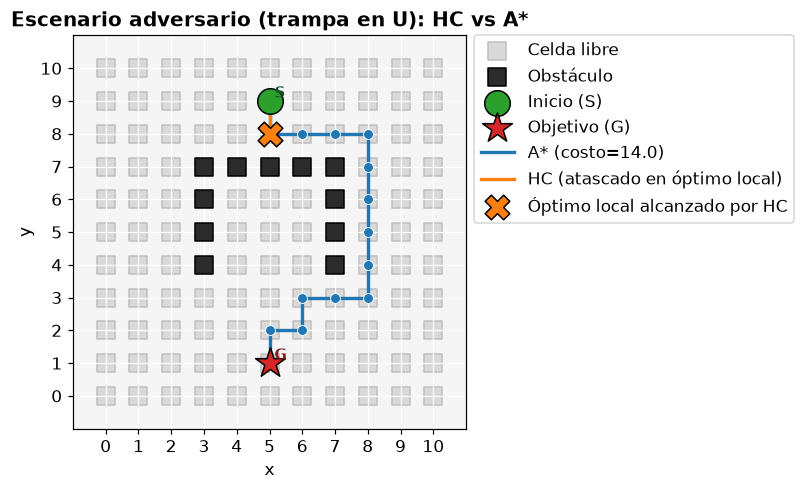

Figura guardada: escenario_trampa.png


In [14]:
fig, ax = plt.subplots(figsize=(7.4, 7.4))
dibujar_base(ax, escenario)
dibujar_camino(ax, escenario, astar_trampa["camino"], "#1f77b4",
               f"A* (costo={astar_trampa['costo_total']:.1f})")
dibujar_camino(ax, escenario, hc_trampa["camino"], "#ff7f0e",
               "HC (atascado en óptimo local)")
final_hc = hc_trampa["camino"][-1]
ax.scatter(*final_hc, s=260, marker="X", c="#ff7f0e", edgecolors="black",
           zorder=6, label="Óptimo local alcanzado por HC")
ax.set_title("Escenario adversario (trampa en U): HC vs A*", fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig("escenario_trampa.png", bbox_inches="tight")
plt.show()
print("Figura guardada: escenario_trampa.png")


## 10. Conclusiones del análisis

1. **Optimalidad y completitud.** A* es completo y óptimo bajo la heurística euclidiana
   admisible y consistente: recupera siempre la ruta de menor costo euclídeo. Hill
   Climbing no ofrece ninguna garantía: su éxito depende del punto de partida y de la
   topología del espacio.
2. **En este dataset HC no falla.** El objetivo está en la esquina inferior derecha y el
   muro de obstáculos es convexo respecto a él; la distancia euclídea decrece de forma
   monótona, de modo que HC alcanza el óptimo global (costo 24) expandiendo incluso menos
   nodos que A*. El barrido desde las 206 celdas libres confirma la ausencia de óptimos
   locales en este escenario particular.
3. **Óptimos locales y mesetas.** El escenario adversario en «U» demuestra la debilidad
   estructural: al abrir la concavidad en dirección opuesta al objetivo, HC queda atrapado
   en un máximo local, mientras A* bordea el obstáculo. Los reinicios aleatorios mitigan
   el problema a costa de evaluar muchos más estados y sin garantía de optimalidad.
4. **Costo computacional.** A* paga su optimalidad con mayor memoria (frontera) y un
   número de expansiones mayor. Hill Climbing, cuando acierta, es más barato por paso,
   pero no es fiable en topologías no convexas.
5. **Idoneidad.** A* es preferible cuando se exige optimalidad o completitud (navegación
   crítica, robótica, planificación). Hill Climbing resulta útil en espacios enormes,
   suaves y con objetivos alcanzables por descenso monótono, donde una solución
   "suficientemente buena" es aceptable y el presupuesto de cómputo es bajo.
